# Chest X-Ray Pneumonia Classification & Grad-CAM Localization (`Torchvision` ResNet-18)
Downloads real pediatric chest radiographs from `medmnist` (`PneumoniaMNIST`), fine-tunes a pretrained `ResNet-18` model with PyTorch Autograd Grad-CAM hooks, and saves `pneumonia_resnet18_gradcam.pth`.

In [ ]:
# !pip install -q medmnist torch torchvision scikit-learn matplotlib numpy

In [2]:
from __future__ import annotations
import random
from typing import Any, Dict, Optional, Tuple
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import torchvision.models as tv_models
from sklearn.metrics import roc_auc_score
from medmnist import PneumoniaMNIST

## Download & Visualize `PneumoniaMNIST` Radiographs

In [3]:
def load_pneumonia_mnist():
    print("Downloading real PneumoniaMNIST Chest X-Ray dataset...")
    train_ds = PneumoniaMNIST(split="train", download=True, size=28)
    test_ds = PneumoniaMNIST(split="test", download=True, size=28)
    print(f"Loaded PneumoniaMNIST | Train: {len(train_ds):,} X-rays | Test: {len(test_ds):,} X-rays")
    return train_ds, test_ds

pneumonia_train, pneumonia_test = load_pneumonia_mnist()

100%|██████████| 4.17M/4.17M [00:06<00:00, 640kB/s]


Loaded PneumoniaMNIST | Train: 4,708 X-rays | Test: 624 X-rays


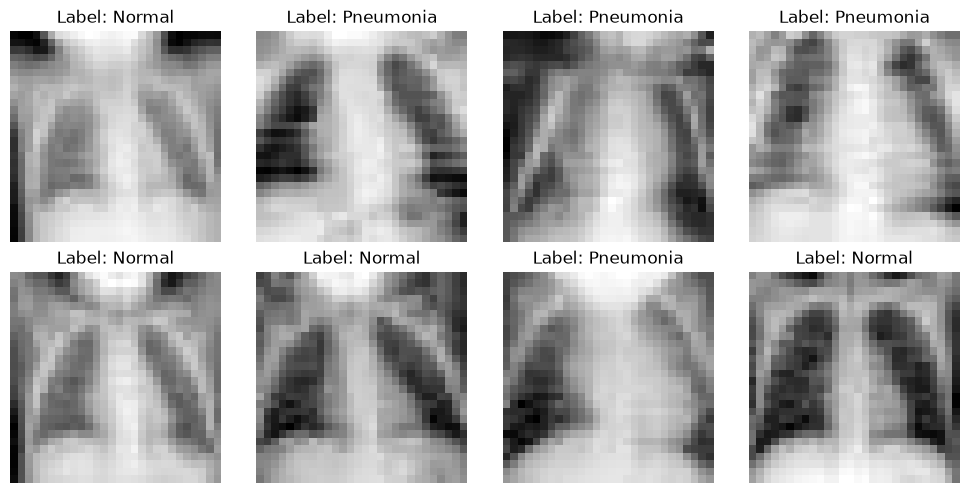

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
class_names = ["Normal", "Pneumonia"]
for ax in axes.flat:
    idx = random.randint(0, len(pneumonia_train) - 1)
    image, label = pneumonia_train[idx]
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {class_names[int(label[0])]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Fine-Tune `TorchvisionChestXRayGradCAM` (ResNet-18 + Autograd Hooks)

In [5]:
class TorchvisionChestXRayGradCAM:
    """Transfer-learned ResNet-18 on PneumoniaMNIST with exact PyTorch Autograd Grad-CAM hooks."""

    def __init__(self):
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.model = tv_models.resnet18(weights=tv_models.ResNet18_Weights.DEFAULT)
        self.model.fc = nn.Linear(self.model.fc.in_features, 1)
        self.model = self.model.to(self.device)

        self._feature_maps: Optional[torch.Tensor] = None
        self._gradients: Optional[torch.Tensor] = None
        self._register_gradcam_hooks()

    def _register_gradcam_hooks(self) -> None:
        target_layer = self.model.layer4[-1]

        def forward_hook(_module, _inp, output):
            self._feature_maps = output

        def backward_hook(_module, _grad_in, grad_out):
            self._gradients = grad_out[0]

        target_layer.register_forward_hook(forward_hook)
        target_layer.register_full_backward_hook(backward_hook)

    @staticmethod
    def _prepare_batch(imgs_uint8: np.ndarray) -> torch.Tensor:
        t = torch.tensor(imgs_uint8, dtype=torch.float32) / 255.0
        if t.ndim == 3:
            t = t.unsqueeze(1)
        elif t.ndim == 4 and t.shape[-1] == 1:
            t = t.permute(0, 3, 1, 2)
        t = F.interpolate(t, size=(64, 64), mode="bilinear", align_corners=False)
        return t.repeat(1, 3, 1, 1)

    def fit(self, train_ds, test_ds, max_train: int = 1200, epochs: int = 4) -> Dict[str, float]:
        X_tr = self._prepare_batch(train_ds.imgs[:max_train])
        y_tr = torch.tensor(train_ds.labels[:max_train].squeeze(), dtype=torch.float32)
        X_te = self._prepare_batch(test_ds.imgs[:400])
        y_te = test_ds.labels[:400].squeeze().astype(int)

        loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=32, shuffle=True)
        optimizer = torch.optim.AdamW(self.model.parameters(), lr=3e-4, weight_decay=1e-4)
        criterion = nn.BCEWithLogitsLoss()

        self.model.train()
        for _ in range(epochs):
            for bx, by in loader:
                bx, by = bx.to(self.device), by.to(self.device)
                optimizer.zero_grad()
                out = self.model(bx).squeeze(-1)
                loss = criterion(out, by)
                loss.backward()
                optimizer.step()

        self.model.eval()
        with torch.no_grad():
            probs = torch.sigmoid(self.model(X_te.to(self.device)).squeeze(-1)).cpu().numpy()

        auc = float(roc_auc_score(y_te, probs))
        print(f"Torchvision ResNet-18 fine-tuned on PneumoniaMNIST | Test ROC-AUC: {auc:.4f}")
        return {"pneumonia_mnist_test_auc": round(auc, 4)}

    def predict_with_gradcam(self, img_28x28: np.ndarray) -> Dict[str, Any]:
        self.model.eval()
        x = self._prepare_batch(img_28x28[None, ...]).to(self.device)
        x.requires_grad_(True)

        self.model.zero_grad()
        logit = self.model(x).squeeze()
        prob = float(torch.sigmoid(logit).item())
        logit.backward()

        grads = self._gradients[0]
        fmaps = self._feature_maps[0]
        weights = grads.mean(dim=(1, 2))
        cam = torch.relu(torch.sum(weights[:, None, None] * fmaps, dim=0))
        cam_up = F.interpolate(cam[None, None, ...], size=(28, 28), mode="bilinear", align_corners=False)[0, 0]
        cam_np = cam_up.detach().cpu().numpy()
        if cam_np.max() > 1e-8:
            cam_np /= cam_np.max()

        r, c = np.unravel_index(np.argmax(cam_np), cam_np.shape)
        side = "Right" if c >= 14 else "Left"
        zone = "Lower Lobe" if r >= 14 else "Upper/Mid Lobe"

        return {
            "pneumonia_probability": round(prob, 4),
            "radiology_impression": f"Pulmonary consolidation localized to {side} {zone}" if prob >= 0.5 else "Clear lung fields without focal opacity",
            "gradcam_hotspot_rc": [int(r), int(c)],
            "gradcam_anatomical_zone": f"{side} {zone}",
        }

## Train & Save Checkpoint (`pneumonia_resnet18_gradcam.pth`)

In [6]:
xray_engine = TorchvisionChestXRayGradCAM()
xray_engine.fit(pneumonia_train, pneumonia_test, max_train=1200, epochs=4)

checkpoint = {
    "model_state_dict": xray_engine.model.state_dict(),
    "model_name": "resnet18",
    "num_classes": 1,
    "input_channels": 3,
    "input_size": (64, 64),
}
torch.save(checkpoint, "pneumonia_resnet18_gradcam.pth")
print("Chest X-ray model saved successfully to pneumonia_resnet18_gradcam.pth!")
print("Sample Grad-CAM prediction:", xray_engine.predict_with_gradcam(pneumonia_test.imgs[5]))

Torchvision ResNet-18 fine-tuned on PneumoniaMNIST | Test ROC-AUC: 0.9651
Chest X-ray model saved successfully to pneumonia_resnet18_gradcam.pth!
Sample Grad-CAM prediction: {'pneumonia_probability': 0.9999, 'radiology_impression': 'Pulmonary consolidation localized to Left Upper/Mid Lobe', 'gradcam_hotspot_rc': [0, 0], 'gradcam_anatomical_zone': 'Left Upper/Mid Lobe'}
